# EDA: Downtown San Diego Homeless Population Analysis
**Task 2.1 — Summary Statistics & Temporal Patterns**

Source: `data/MasterCounts_Adjusted_v2.csv` (canonical adjusted counts, Task 1.3 deliverable)

This notebook covers:
1. Data load & scoping
2. Summary statistics (overall & by neighborhood)
3. Monthly seasonality
4. Year-over-year % change (overall & by neighborhood)
5. Top 3 neighborhoods by average count and by growth rate


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 120)
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

MONTH_ORDER = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']


## 1. Load Data & Scope

The canonical dataset is stored **long-format**: each area-month can have up to 4 rows
(`component` = `total`, `individual`, `vehicle`, `tent`). For headline population analysis
we use `component == 'total'` to avoid double-counting.

`area_type` distinguishes 7 top-level **neighborhoods** (incl. `East Village` as a parent)
from 4 **East Village sub-areas** (`North East EV`, `North West EV`, `South East EV`, `South West EV`).
Primary analysis uses `area_type == 'neighborhood'`; sub-areas are examined separately where relevant.


In [2]:
df = pd.read_csv('data/MasterCounts_Adjusted_v2.csv', parse_dates=['date'])
print(f"Rows: {len(df):,}  |  Date range: {df['date'].min().date()} to {df['date'].max().date()}")
df.head()


Rows: 2,814  |  Date range: 2017-01-01 to 2025-12-01


,date,year,month,area,source_area,component,area_type,method,raw_count,total_count
0,2021-01-01,2021,Jan,East Village,East Village,total,neighborhood,POST2020,409.0,409.12
1,2021-01-01,2021,Jan,City Center,City Center,total,neighborhood,POST2020,153.0,153.03
2,2021-01-01,2021,Jan,Columbia,Columbia,total,neighborhood,POST2020,55.0,54.50
3,2021-01-01,2021,Jan,Marina,Marina,total,neighborhood,POST2020,20.0,20.00
4,2021-01-01,2021,Jan,Cortez,Cortez,total,neighborhood,POST2020,47.0,47.00


In [3]:
# Scope to headline totals, neighborhood-level areas
totals = df[(df['component'] == 'total') & (df['area_type'] == 'neighborhood')].copy()
totals['month'] = pd.Categorical(totals['month'], categories=MONTH_ORDER, ordered=True)

print(f"Neighborhood-level total rows: {len(totals):,}")
print(f"Neighborhoods ({totals['area'].nunique()}): {sorted(totals['area'].unique())}")
print(f"Nulls in total_count: {totals['total_count'].isna().sum()}")
totals[['date','year','month','area','total_count']].head()


Neighborhood-level total rows: 708
Neighborhoods (7): ['City Center', 'Columbia', 'Cortez', 'East Village', 'Gaslamp', 'Marina', 'Outside Perimeter']
Nulls in total_count: 28


,date,year,month,area,total_count
0,2021-01-01,2021,Jan,East Village,409.12
1,2021-01-01,2021,Jan,City Center,153.03
2,2021-01-01,2021,Jan,Columbia,54.50
3,2021-01-01,2021,Jan,Marina,20.00
4,2021-01-01,2021,Jan,Cortez,47.00


## 2. Summary Statistics

Mean, median, min, max, and standard deviation of monthly counts — overall and by neighborhood.


In [4]:
overall_stats = totals['total_count'].agg(['mean','median','min','max','std']).round(2)
print("Overall monthly count statistics (all neighborhoods, all months):")
overall_stats


Overall monthly count statistics (all neighborhoods, all months):


mean      156.78
median     58.88
min         0.00
max       921.05
std       197.38
Name: total_count, dtype: float64

In [5]:
by_neighborhood_stats = (
    totals.groupby('area')['total_count']
    .agg(['mean','median','min','max','std','count'])
    .round(2)
    .sort_values('mean', ascending=False)
)
print("Summary statistics by neighborhood (sorted by mean):")
by_neighborhood_stats


Summary statistics by neighborhood (sorted by mean):


,mean,median,min,max,std,count
area,,,,,,
East Village,552.77,504.85,260.59,921.05,157.09,104
Outside Perimeter,217.57,185.50,0.00,640.00,177.92,56
City Center,171.81,156.67,91.00,342.31,54.80,104
Cortez,59.52,51.88,16.00,170.46,30.22,104
Gaslamp,48.43,46.12,18.50,93.00,14.00,104
Columbia,44.49,45.12,13.75,84.50,13.72,104
Marina,30.94,27.38,4.06,79.00,15.82,104


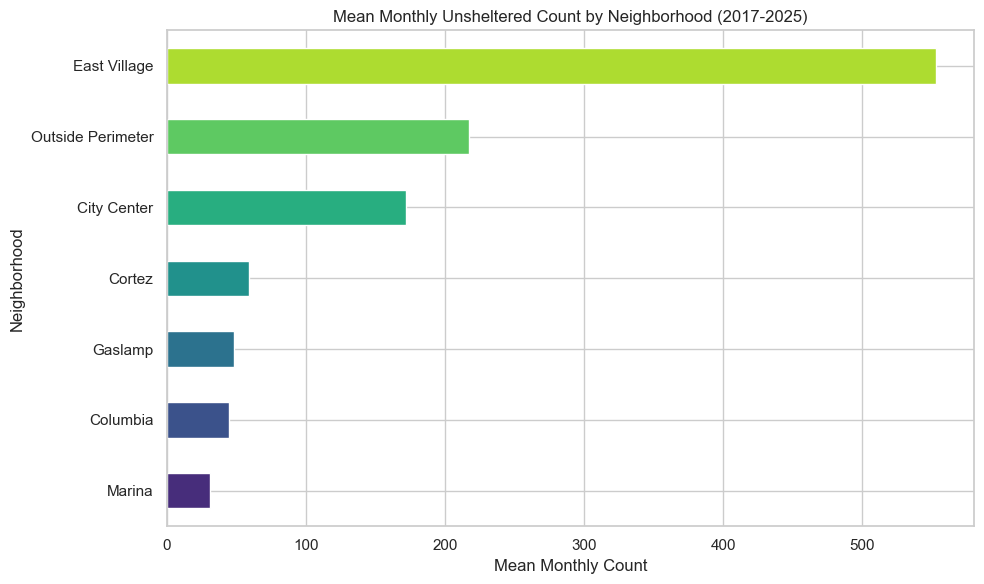

In [6]:
fig, ax = plt.subplots(figsize=(10, 6))
by_neighborhood_stats['mean'].sort_values().plot(kind='barh', ax=ax, color=sns.color_palette('viridis', len(by_neighborhood_stats)))
ax.set_xlabel('Mean Monthly Count')
ax.set_ylabel('Neighborhood')
ax.set_title('Mean Monthly Unsheltered Count by Neighborhood (2017-2025)')
plt.tight_layout()
plt.show()


## 3. Monthly Seasonality

Average count by calendar month across all years — overall and by neighborhood — to identify
consistently high and low months.


In [7]:
seasonality_overall = (
    totals.groupby('month', observed=True)['total_count']
    .agg(['mean','std','count'])
    .round(2)
    .reindex(MONTH_ORDER)
)
print("Overall seasonality (avg count by calendar month, across all years):")
seasonality_overall


Overall seasonality (avg count by calendar month, across all years):


,mean,std,count
month,,,
Jan,157.68,199.00,59
Feb,161.76,195.43,59
Mar,148.67,187.34,59
Apr,153.53,189.95,59
May,160.93,197.06,59
Jun,159.30,198.93,59
Jul,160.48,211.42,52
Aug,161.61,216.38,52
Sep,153.63,207.85,59


In [8]:
high_months = seasonality_overall['mean'].nlargest(3)
low_months = seasonality_overall['mean'].nsmallest(3)
print("Top 3 highest-count months (overall):")
print(high_months)
print("\nTop 3 lowest-count months (overall):")
print(low_months)


Top 3 highest-count months (overall):
month
Feb    161.76
Aug    161.61
May    160.93
Name: mean, dtype: float64

Top 3 lowest-count months (overall):
month
Mar    148.67
Nov    153.43
Apr    153.53
Name: mean, dtype: float64


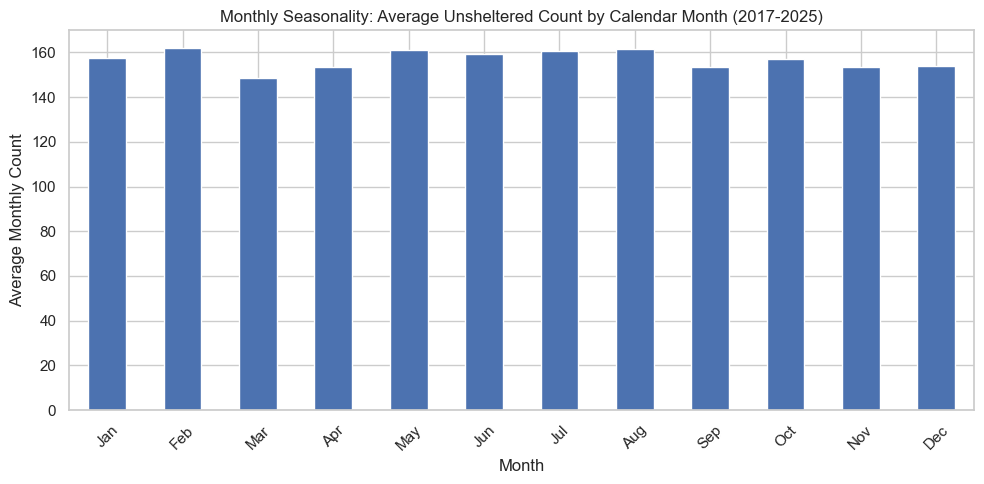

In [9]:
fig, ax = plt.subplots(figsize=(10, 5))
seasonality_overall['mean'].plot(kind='bar', ax=ax, color='#4C72B0')
ax.set_ylabel('Average Monthly Count')
ax.set_xlabel('Month')
ax.set_title('Monthly Seasonality: Average Unsheltered Count by Calendar Month (2017-2025)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:
seasonality_by_neighborhood = (
    totals.pivot_table(index='area', columns='month', values='total_count', aggfunc='mean', observed=True)
    .reindex(columns=MONTH_ORDER)
    .round(1)
)
print("Seasonality by neighborhood (avg count per calendar month):")
seasonality_by_neighborhood


Seasonality by neighborhood (avg count per calendar month):


month,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
area,,,,,,,,,,,,
City Center,167.8,187.9,181.4,168.8,184.8,170.6,164.5,171.7,155.8,177.3,167.3,163.1
Columbia,44.7,47.4,38.4,45.8,47.7,49.7,42.1,48.0,43.1,43.2,42.7,40.9
Cortez,74.2,75.0,51.7,56.4,56.2,52.4,62.7,51.1,57.7,52.9,57.6,64.9
East Village,554.3,546.8,509.4,509.3,530.5,547.6,601.4,603.9,587.9,568.7,533.4,550.9
Gaslamp,47.9,51.1,53.9,42.7,51.0,43.5,39.8,47.1,57.3,50.1,47.4,48.3
Marina,31.4,30.2,28.8,27.5,27.4,32.1,24.8,40.7,33.0,30.6,37.8,28.1
Outside Perimeter,204.0,219.8,199.8,281.0,283.2,267.2,215.8,176.0,130.2,194.2,222.2,205.0


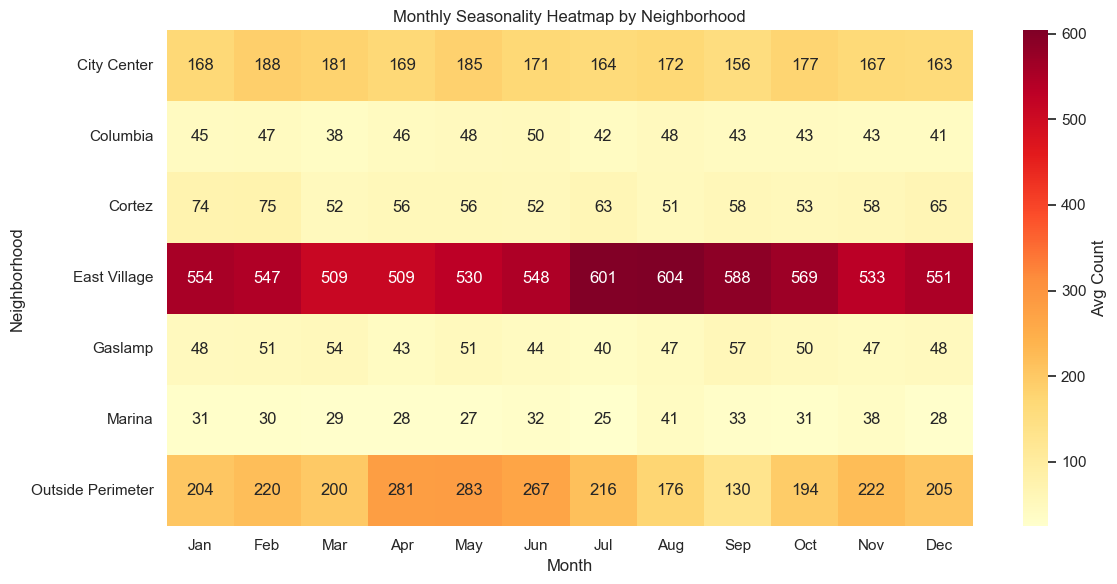

In [11]:
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(seasonality_by_neighborhood, cmap='YlOrRd', annot=True, fmt='.0f', ax=ax, cbar_kws={'label': 'Avg Count'})
ax.set_title('Monthly Seasonality Heatmap by Neighborhood')
ax.set_xlabel('Month')
ax.set_ylabel('Neighborhood')
plt.tight_layout()
plt.show()


## 4. Year-over-Year % Change

Annual totals (mean monthly count per year, since not every year has 12 reporting months)
and the resulting year-over-year percentage change — overall and by neighborhood.

> **Caveat:** 2017 has only 6 reporting months (72 rows / 12 neighborhoods) and 2025 has
> incomplete/unreleased late-year data (see `docs/DataQualityReport.md`). YoY figures
> touching these edge years should be read with that in mind.


In [12]:
annual_overall = totals.groupby('year')['total_count'].mean().round(2)
yoy_overall = annual_overall.pct_change().mul(100).round(2)

yoy_table = pd.DataFrame({'avg_monthly_count': annual_overall, 'yoy_pct_change': yoy_overall})
print("Overall annual average count & YoY % change:")
yoy_table


Overall annual average count & YoY % change:


,avg_monthly_count,yoy_pct_change
year,,
2017,176.31,NaN
2018,142.84,-18.98
2019,135.79,-4.94
2020,109.02,-19.71
2021,137.20,25.85
2022,216.27,57.63
2023,223.98,3.56
2024,126.50,-43.52
2025,122.78,-2.94


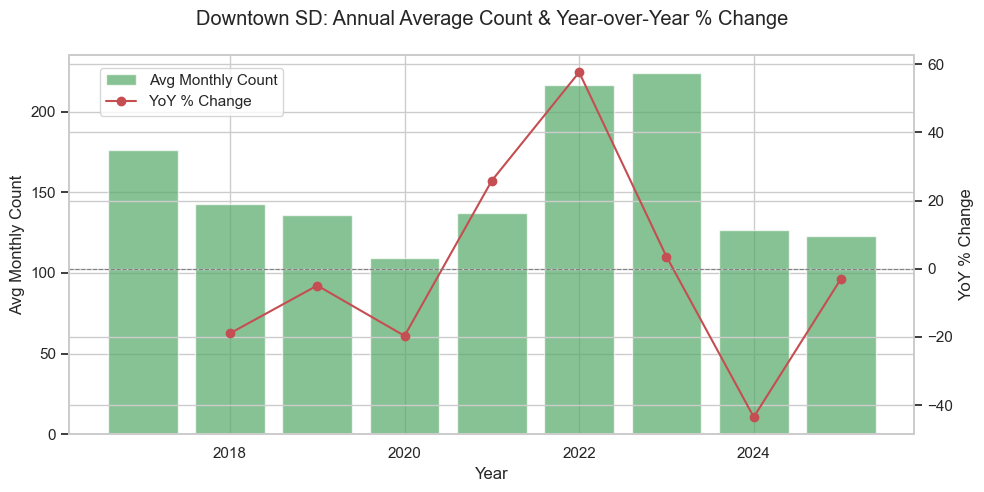

In [13]:
fig, ax1 = plt.subplots(figsize=(10, 5))
ax1.bar(yoy_table.index, yoy_table['avg_monthly_count'], color='#55A868', alpha=0.7, label='Avg Monthly Count')
ax1.set_ylabel('Avg Monthly Count')
ax1.set_xlabel('Year')

ax2 = ax1.twinx()
ax2.plot(yoy_table.index, yoy_table['yoy_pct_change'], color='#C44E52', marker='o', label='YoY % Change')
ax2.set_ylabel('YoY % Change')
ax2.axhline(0, color='gray', linewidth=0.8, linestyle='--')

fig.suptitle('Downtown SD: Annual Average Count & Year-over-Year % Change')
fig.legend(loc='upper left', bbox_to_anchor=(0.1, 0.88))
plt.tight_layout()
plt.show()


In [14]:
annual_by_neighborhood = totals.pivot_table(index='year', columns='area', values='total_count', aggfunc='mean')
yoy_by_neighborhood = annual_by_neighborhood.pct_change().mul(100).round(2)
print("YoY % change by neighborhood (rows=year, cols=neighborhood):")
yoy_by_neighborhood


YoY % change by neighborhood (rows=year, cols=neighborhood):


area,City Center,Columbia,Cortez,East Village,Gaslamp,Marina,Outside Perimeter
year,,,,,,,
2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2018,-6.10,-5.53,-15.39,-24.88,8.64,-23.94,NaN
2019,-9.15,11.14,-7.07,-5.55,3.10,-8.27,NaN
2020,-7.82,-1.89,-26.60,-22.51,-25.75,-31.85,NaN
2021,16.55,15.57,11.84,25.40,-14.87,4.94,NaN
2022,65.55,-10.92,129.43,50.26,38.86,19.29,87.09
2023,-0.01,-32.69,22.93,10.84,-17.81,-31.10,-1.92
2024,-19.72,7.79,-18.41,-44.09,11.85,-16.42,-80.67
2025,-17.84,-18.96,-28.41,-2.88,-22.75,-25.93,103.08


## 5. Top 3 Neighborhoods

By **average count** (overall magnitude) and by **growth rate** (average YoY % change,
excluding the 2017 stub year and treating 2025 with caution due to incomplete data).


In [15]:
top3_by_avg_count = by_neighborhood_stats['mean'].nlargest(3)
print("Top 3 neighborhoods by average monthly count:")
top3_by_avg_count


Top 3 neighborhoods by average monthly count:


area
East Village         552.77
Outside Perimeter    217.57
City Center          171.81
Name: mean, dtype: float64

In [16]:
# Average YoY growth rate per neighborhood, excluding the 2017->2018 transition
# (2017 is a partial/stub year) for a fairer growth comparison.
growth_rate = yoy_by_neighborhood.loc[2019:].mean().round(2).sort_values(ascending=False)
top3_by_growth = growth_rate.head(3)
print("Average YoY % growth rate by neighborhood (2019 onward):")
print(growth_rate)
print("\nTop 3 neighborhoods by average growth rate:")
top3_by_growth


Average YoY % growth rate by neighborhood (2019 onward):
area
Outside Perimeter    26.90
Cortez               11.96
City Center           3.94
East Village          1.64
Gaslamp              -3.91
Columbia             -4.28
Marina              -12.76
dtype: float64

Top 3 neighborhoods by average growth rate:


area
Outside Perimeter    26.90
Cortez               11.96
City Center           3.94
dtype: float64

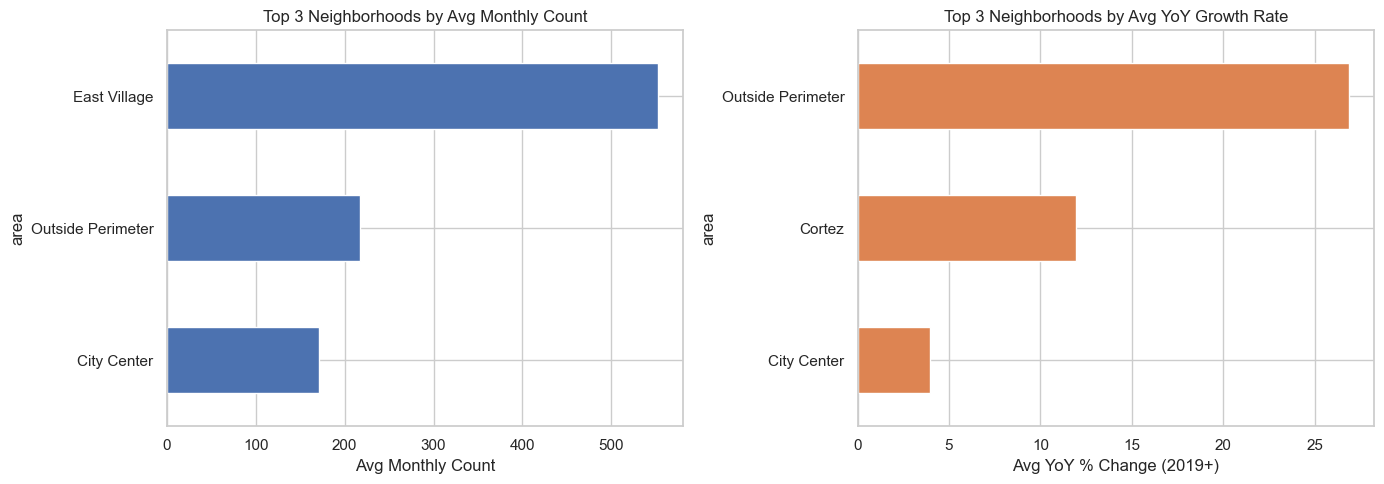

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

top3_by_avg_count.sort_values().plot(kind='barh', ax=axes[0], color='#4C72B0')
axes[0].set_title('Top 3 Neighborhoods by Avg Monthly Count')
axes[0].set_xlabel('Avg Monthly Count')

top3_by_growth.sort_values().plot(kind='barh', ax=axes[1], color='#DD8452')
axes[1].set_title('Top 3 Neighborhoods by Avg YoY Growth Rate')
axes[1].set_xlabel('Avg YoY % Change (2019+)')

plt.tight_layout()
plt.show()


## Summary of Findings

- **Overall scale:** Across 2017-2025, neighborhood-level monthly counts (7 neighborhoods, `component == total`) average **156.8** (median 58.9, std 197.4), reflecting a highly skewed distribution driven by East Village.
- **By neighborhood (avg monthly count):** East Village (552.8) >> Outside Perimeter (217.6) > City Center (171.8) > Cortez (59.5) > Gaslamp (48.4) > Columbia (44.5) > Marina (30.9).
- **Seasonality:** Counts are relatively flat month-to-month (range ~149-162 overall), with **Feb (161.8), Aug (161.6), and May (160.9)** running highest and **Mar (148.7), Nov (153.4), and Apr (153.5)** running lowest. East Village itself peaks in **Jul-Aug** (601-604) and dips in spring (Mar-Apr, ~509).
- **YoY trend:** Overall average count fell steadily 2018-2020 (COVID-era lows, -19.7% in 2020), rebounded sharply in 2021-2022 (+25.9%, +57.6%, peaking at 224 in 2023), then dropped again in 2024 (-43.5%) before roughly stabilizing in 2025 (-2.9%).
- **Top 3 by average count:** East Village, Outside Perimeter, City Center.
- **Top 3 by avg YoY growth rate (2019+):** Outside Perimeter (+26.9%), Cortez (+12.0%), City Center (+3.9%) - these diverge from the magnitude ranking (Marina and Columbia are shrinking, at -12.8% and -4.3% respectively), showing growth is not concentrated in the largest-count areas.
- **Caveat:** Outside Perimeter has only 56 observations (partial coverage since 2022) and 28 nulls remain in the neighborhood-level total_count column (2025 unreleased months); YoY figures for 2022 and 2025 for that area should be read with caution.

*Narrative to be finalized in Task 2.3 (Summary Report & Presentation) after full visual review.*
